# 01. Data and split
**Lead: Keshav.** Goal: check the data and keep past and future separate.

`Class = 0` means legitimate. `Class = 1` means fraud. Class is an answer used for filtering and
evaluation, never an input feature. `Time` is elapsed seconds, so it orders the transactions.

In [1]:
from pathlib import Path
import os, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image

# Find the project even if Jupyter starts inside phase2/notebooks.
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "CSAI_Project_Instructions_Phase_1_and_Phase_2.pdf").exists())
P2 = ROOT / "phase2"
for folder in ["results", "figures", "models", "output"]:
    (P2 / folder).mkdir(exist_ok=True)
plt.rcParams.update({"figure.figsize": (8, 4), "font.size": 11,
                     "axes.spines.top": False, "axes.spines.right": False})

def show(name):
    plt.tight_layout()
    plt.savefig(P2 / "figures" / name, dpi=150, bbox_inches="tight")
    display(Image(filename=str(P2 / "figures" / name), width=850))
    plt.close()

## 1. Load the real dataset
We use the existing ULB/Kaggle CSV. Missing data causes a clear error instead of a silent synthetic fallback.
Source: https://www.kaggle.com/datasets/mlg-ulb/creditcardfraud

In [2]:
import hashlib
csv_path = ROOT / "phase1/data/raw/creditcard.csv"
assert csv_path.exists(), "Download creditcard.csv from the documented dataset into phase1/data/raw/."
raw = pd.read_csv(csv_path)
expected = ["Time"] + [f"V{i}" for i in range(1, 29)] + ["Amount", "Class"]
assert list(raw.columns) == expected
assert raw.isna().sum().sum() == 0
assert np.isfinite(raw.to_numpy()).all()
assert set(raw["Class"].unique()) == {0, 1}
assert (raw[["Amount", "Time"]] >= 0).all().all()
sha256 = hashlib.sha256(csv_path.read_bytes()).hexdigest()
old_sha = json.loads((ROOT / "phase1/results/run_info.json").read_text())["raw_sha256"]
assert sha256 == old_sha, "Dataset differs from the Phase 1 benchmark. Investigate before comparison."
print(f"Raw: {len(raw):,} transactions, {int(raw.Class.sum())} frauds")
print("Missing cells: 0; infinite values: 0")

Raw: 284,807 transactions, 492 frauds
Missing cells: 0; infinite values: 0


## 2. Remove exact repeats, then split by time
We retain Phase 1's assumption that exact duplicate rows are repeated records. Without transaction IDs,
we cannot prove that every duplicate is an accidental copy. Removing them avoids exact repeats across periods.
Keep this assumption visible when discussing results.

Training = earliest 60%; validation = next 20%; test = last 20%.
Training teaches the model. Validation controls stopping and cutoffs. Test reports the final comparison.

In [3]:
data = raw.sort_values("Time", kind="stable").drop_duplicates().reset_index(drop=True)
n = len(data)
train_end, validation_end = int(0.6*n), int(0.8*n)
parts = {"train": data.iloc[:train_end],
         "validation": data.iloc[train_end:validation_end],
         "test": data.iloc[validation_end:]}
rows = []
for name, part in parts.items():
    part.to_csv(P2 / "models" / f"{name}.csv", index=False)
    rows.append({"split": name, "rows": len(part), "frauds": int(part.Class.sum()),
                 "legitimate": int((part.Class == 0).sum()),
                 "fraud_rate_pct": 100*part.Class.mean(),
                 "first_second": part.Time.min(), "last_second": part.Time.max()})
splits = pd.DataFrame(rows)
display(splits.round(4))
assert list(splits.rows) == [170235, 56745, 56746]
assert list(splits.frauds) == [342, 57, 74]
assert parts["train"].Time.max() <= parts["validation"].Time.min()
assert parts["validation"].Time.max() <= parts["test"].Time.min()
splits.to_csv(P2 / "results/splits.csv", index=False)
(P2 / "results/data_audit.json").write_text(json.dumps({
    "raw_sha256": sha256, "raw_rows": len(raw), "raw_frauds": int(raw.Class.sum()),
    "duplicates_removed": len(raw)-n, "clean_rows": n,
    "clean_frauds": int(data.Class.sum()), "missing_cells": 0,
    "duplicate_policy": "Remove exact repeats, preserving Phase 1 assumption"}, indent=2))

Out[3]: 305


,split,rows,frauds,legitimate,fraud_rate_pct,first_second,last_second
0,train,170235,342,169893,0.2009,0.0,120392.0
1,validation,56745,57,56688,0.1004,120393.0,145233.0
2,test,56746,74,56672,0.1304,145234.0,172792.0


## 3. Visual: fraud is rare and its frequency changes
The left plot uses counts; the right uses percentages. Neither model is trained to maximize accuracy.
At test prevalence, always predicting legitimate would be about 99.87% accurate while catching no fraud.

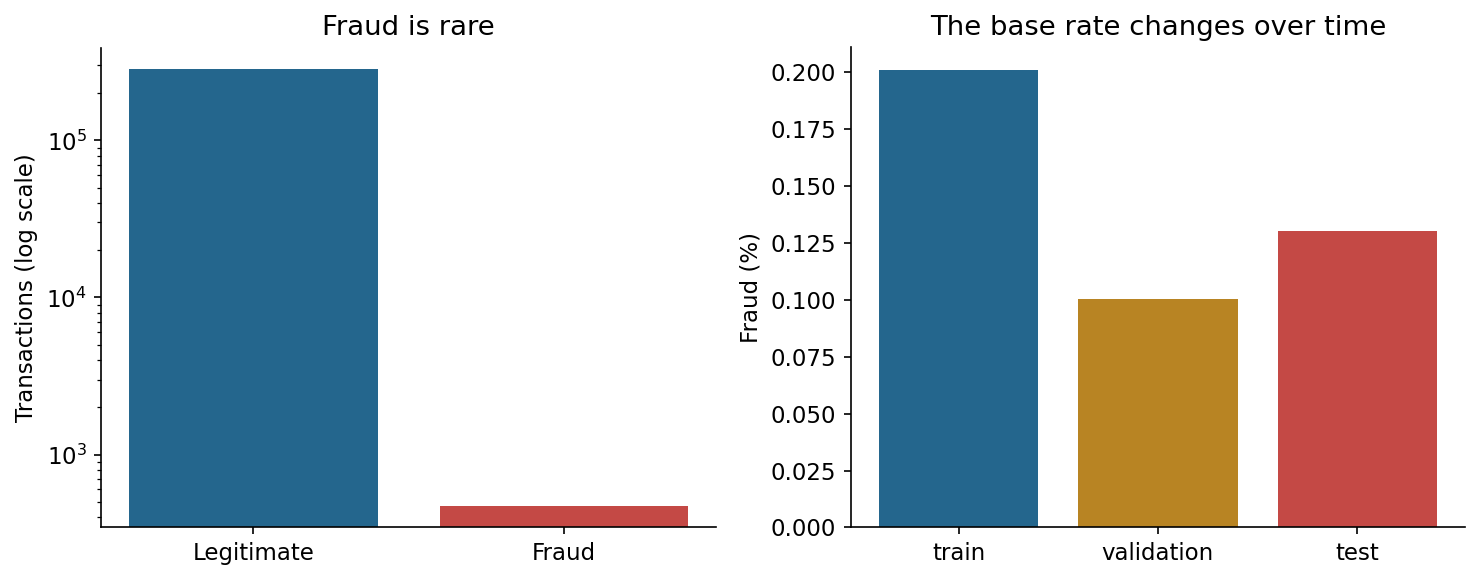

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ax[0].bar(["Legitimate", "Fraud"], [(data.Class == 0).sum(), data.Class.sum()], color=["#24668d", "#c44945"])
ax[0].set_yscale("log")
ax[0].set_ylabel("Transactions (log scale)")
ax[0].set_title("Fraud is rare")
ax[1].bar(splits.split, splits.fraud_rate_pct, color=["#24668d", "#b88423", "#c44945"])
ax[1].set_ylabel("Fraud (%)")
ax[1].set_title("The base rate changes over time")
show("01_data.png")

**Say in the viva:** We train on the past and test on later transactions. The test has 74 frauds among
56,746 transactions, so each detected fraud changes recall by about 1.35 percentage points.
This is two days of historical data, not evidence of long-term bank performance.